# FARS Road-Accident Severity Classification

Four machine-learning pipelines (logistic regression, SVM, random forest, k-NN) compared with stratified 5-fold cross-validation.


In [1]:
#connect google drive to this google colab notebook
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


---
---
## Dataset 1: Classification

The dataset, called FARS, is a collection of statistics of US road traffic accidents. The class label (target variable) is about the severity of the accident. It has 20 features and over 100K examples. The dataset can be found in Canvas as a CSV file ("fars.csv"), located alongside this notebook, in which the last column contains the class labels.

## What you need to do:

You will need to perform the following steps on the dataset:
1. EDA
2. Data preprocessing
3. Split the data into training and test sets using cross-validation
4. Develop **FOUR** machine learning pipelines for classifying the severity of the accident
5. Present the results for your pipeline using the most appropriate set of metrics.
6. Provide a short report on which approaches you used and which gave the best results. It would be good to consider why particular pipelines gave the best results.

Some help for good marks:
- We expect that you evaluate a very broad range of options for the design of your machine learning pipelines, including (but not limited to) data preprocessing, feature/instance selection, class imbalance correction, several (appropriate) machine learning pipelines and hyperparameter tuning.


# Your answer below

##1. Introduction


Road traffic accidents continue to be a major public safety concern and understanding the different factors influencing accident severity is an important step towards better road safety conditions.The **Fatality Analysis Reporting System (FARS)** dataset contains detailed records of the traffic accidents in the United States.It contains information about the different factors and conditions of each accident.

This mini-project presents a supervised classification aiming at predict road traffic accident severity based on the available features that describe the individual and their surroundings.Machine learning methodologies are particularly useful for this problem given the large size of the dataset with potential complex and non-linear correlations between accident attributes and severity outcomes.

The aim of this study is to examine the performance of different classification pipelines on the given dataset and to explore whether machine learning can accurately predict accident severity.To achieve this, an exploratory data analysis is initially carried out to understand the characteristics and structure of the dataset.Appropriate data preprocessing techniques are then applied, following which four different machine learning pipelines are designed, implemented and then evaluated. Standard classification metrics are used to compare these pipelines and evaluate their strengths and limitations.

## 2. Dataset Exploration



The first step before exploring the data is load the dataset -fars.csv file which has been uploaded to the google drive.

In [2]:
#set path and using pandas to access and read the dataset
import pandas as pd

data_path = "/content/drive/MyDrive/machine_learning/aasignment/fars.csv"
df = pd.read_csv(data_path)
#Dataset is loaded and saved as df to access the data.

Examining the Fars dataset's general structure and basic properties is the first step in the exploration process.This entails looking at ,number of observation and features ,and analysing a small samples of this data.

####2.1 Dataset Overview

In [3]:
df.shape

(100968, 30)

In [4]:
df.head()

,CASE_STATE,AGE,SEX,PERSON_TYPE,SEATING_POSITION,RESTRAINT_SYSTEM-USE,AIR_BAG_AVAILABILITY/DEPLOYMENT,EJECTION,EJECTION_PATH,EXTRICATION,...,DRUG_TEST_RESULTS_(2_of_3),DRUG_TEST_TYPE_(3_of_3),DRUG_TEST_RESULTS_(3_of_3),HISPANIC_ORIGIN,TAKEN_TO_HOSPITAL,RELATED_FACTOR_(1)-PERSON_LEVEL,RELATED_FACTOR_(2)-PERSON_LEVEL,RELATED_FACTOR_(3)-PERSON_LEVEL,RACE,INJURY_SEVERITY
0,Alabama,34,Male,Driver,Front_Seat_-_Left_Side_(Drivers_Side),None_Used/Not_Applicable,Air_Bag_Available_but_Not_Deployed_for_this_Seat,Totally_Ejected,Unknown,Not_Extricated,...,0,Not_Tested_for_Drugs,0,Non-Hispanic,No,Not_Applicable_-_Driver/None_-_All_Other_Persons,Not_Applicable_-_Driver/None_-_All_Other_Persons,Not_Applicable_-_Driver/None_-_All_Other_Persons,White,Fatal_Injury
1,Alabama,20,Male,Driver,Front_Seat_-_Left_Side_(Drivers_Side),None_Used/Not_Applicable,Deployed_Air_Bag_from_Front,Totally_Ejected,Unknown,Not_Extricated,...,0,Not_Tested_for_Drugs,0,Non-Hispanic,No,Not_Applicable_-_Driver/None_-_All_Other_Persons,Not_Applicable_-_Driver/None_-_All_Other_Persons,Not_Applicable_-_Driver/None_-_All_Other_Persons,White,Fatal_Injury
2,Alabama,43,Male,Driver,Front_Seat_-_Left_Side_(Drivers_Side),Lap_and_Shoulder_Belt,Air_Bag_Not_Available_for_this_Seat,Not_Ejected,Not_Ejected/Not_Applicable,Extricated,...,0,Not_Tested_for_Drugs,0,Non-Hispanic,No,Not_Applicable_-_Driver/None_-_All_Other_Persons,Not_Applicable_-_Driver/None_-_All_Other_Persons,Not_Applicable_-_Driver/None_-_All_Other_Persons,Black,Fatal_Injury
3,Alabama,38,Female,Passenger_of_a_Motor_Vehicle_in_Transport,Front_Seat_-_Right_Side,Lap_and_Shoulder_Belt,Air_Bag_Not_Available_for_this_Seat,Not_Ejected,Not_Ejected/Not_Applicable,Extricated,...,0,Not_Tested_for_Drugs,0,Not_a_Fatality_(Not_Applicable),Yes,Not_Applicable_-_Driver/None_-_All_Other_Persons,Not_Applicable_-_Driver/None_-_All_Other_Persons,Not_Applicable_-_Driver/None_-_All_Other_Persons,Not_a_Fatality_(Not_Applicable),Incapaciting_Injury
4,Alabama,50,Male,Driver,Front_Seat_-_Left_Side_(Drivers_Side),Lap_and_Shoulder_Belt,Deployed_Air_Bag_from_Front,Not_Ejected,Not_Ejected/Not_Applicable,Not_Extricated,...,0,Not_Tested_for_Drugs,0,Non-Hispanic,Yes,Not_Applicable_-_Driver/None_-_All_Other_Persons,Not_Applicable_-_Driver/None_-_All_Other_Persons,Not_Applicable_-_Driver/None_-_All_Other_Persons,Black,Fatal_Injury


This dataset contains a large number of records, with each row representing an individual involved in a road traffic accident. The columns collect a range of information.It records the demographic,sitting position of the victim,safety system usage, and indicators od alcohol or drug involvement. This validates that the dataset is suitable for a supervised machine learning approach.

#### 2.2 Feature Types and Data Structure

In [5]:
#display data types and non null counts.
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100968 entries, 0 to 100967
Data columns (total 30 columns):
 #   Column                               Non-Null Count   Dtype 
---  ------                               --------------   ----- 
 0   CASE_STATE                           100968 non-null  object
 1   AGE                                  100968 non-null  int64 
 2   SEX                                  100968 non-null  object
 3   PERSON_TYPE                          100968 non-null  object
 4   SEATING_POSITION                     100968 non-null  object
 5   RESTRAINT_SYSTEM-USE                 100968 non-null  object
 6   AIR_BAG_AVAILABILITY/DEPLOYMENT      100968 non-null  object
 7   EJECTION                             100968 non-null  object
 8   EJECTION_PATH                        100968 non-null  object
 9   EXTRICATION                          100968 non-null  object
 10  NON_MOTORIST_LOCATION                100968 non-null  object
 11  POLICE_REPORTED_ALCOHOL_IN

This dataset is a collection of bot numerical and categorical datatypes.Numberical data ,present here gives information about victims age , alcohol  and drug results.Categorical data describes characteristics such us demographic ,seating position ,safety system used ,airbag status.This varability in the data suggest that suitable preprocessing is essential before deploying machine learning models.

#### 2.3 Target Variable Distribution

As this is study is formulated as a classification problem, it is important to analyse the target variable reflecting accident severity.Understanding its distribution and how balenced the dataset is, facilitates the use of more approriate evaluation metrics.

In [6]:
df['INJURY_SEVERITY'].value_counts()

,count
INJURY_SEVERITY,
Fatal_Injury,42116
No_Injury,20007
Incapaciting_Injury,15072
Nonincapaciting_Evident_Injury,13890
Possible_Injury,8674
Unknown,901
Injured_Severity_Unknown,299
Died_Prior_to_Accident,9


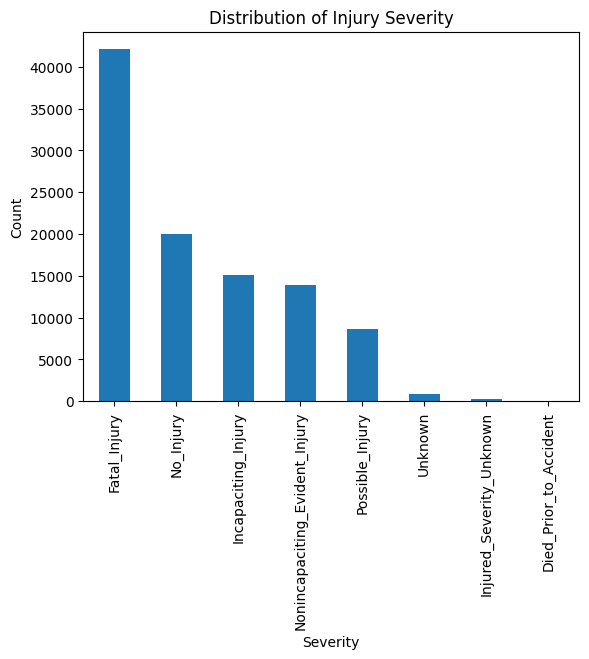

In [7]:
import matplotlib.pyplot as plt

df['INJURY_SEVERITY'].value_counts().plot(kind='bar')
plt.title('Distribution of Injury Severity')
plt.xlabel('Severity')
plt.ylabel('Count')
plt.show()

This distribution of the target variable INJURY_SEVERITY indicates that the data is highly imbalanced ,with some severity classes occuring much more frequently than others .In perticular Fatel_injury class is common ,followed by No_injury,while several other categories appear rearly .This type distribution is a charecteristic of real-world road accident data and has important implication for model selection.

####2.4 Missing and Unknown Values

As we know that this dataset is a real-world dataset, it often contains missing or unknown values due to reporting limitations. Indentifying the extent of missing values before preprocessign and handling them is crucial as it directly influences the model performance.

In [8]:
df.isnull().sum().sort_values(ascending = False).head(10)

,0
CASE_STATE,0
AGE,0
SEX,0
PERSON_TYPE,0
SEATING_POSITION,0
RESTRAINT_SYSTEM-USE,0
AIR_BAG_AVAILABILITY/DEPLOYMENT,0
EJECTION,0
EJECTION_PATH,0
EXTRICATION,0


After examining the values ,it is evident that there are no missing or unknown values explicitly .However,several feature include catogories such as "Unknown", "Not_Extricated", ect. ,representing missing or unavailable information.This indicates that the missing information in this dataset is encoded implicitly rather than expllicitly, which is typica for a real world recorded data and hence it has to be handled in the data prepocessing with caution.

In [9]:
df.nunique().sort_values()

,0
SEX,3
EXTRICATION,3
TAKEN_TO_HOSPITAL,3
POLICE_REPORTED_ALCOHOL_INVOLVEMENT,4
POLICE-REPORTED_DRUG_INVOLVEMENT,4
EJECTION,4
METHOD_OF_DRUG_DETERMINATION,5
METHOD_ALCOHOL_DETERMINATION,7
DRUG_TEST_TYPE_(1_of_3),7
DRUG_TEST_TYPE_(2_of_3),7


After analysing the output we can say that this dataset is hetrogeneous , having most of the features as categorical .It is also evident that the cardinality of diffent information varies widly ,some having low cardinality mostly repesent binary or very few unique valus like sex, extriction,take to hospital post accident ,recorded by police about alcohol, and ejection.Moving forward some feature have moderate cardinality , helping for more detailed accident and seating charecteristics, like person type like driver ,passender ,ect. ,type of alcohol test used , security system used like aribag .Their are some features which has even higher cardinality like age ,state identifiers ,while the drug and alcohol represent several numerous coded values.This variation in feature cardinality indicates that various machine learning models will react diffrently with the data and has to be handled meticulously in the design of each pipeline.

##3 Data Processing

Data preprocessing is a crucial step in the machine learning pipeline.Based on the exploratory data analysis, the faras dataset contains a mixture of numerical and categorical features ,with missing information encoded implicitly throught diffrent categories insted of using null values.step ,numerical data and categorical data should be handled seperatly.To ensure a fair and reproducible comparision between machine learning models all preprocessing steps are incorporated directly within each pipeline.This design prevents data leakage and allows preprocessing steps are incorporated directly into each pipeline.This design prevents data leakage and allows preprocessing parameters to be learned exclusively from training data during cross validation.
Numerical and categorical features are handled separately.




#### 3.1 Separation of Features and Target

In [10]:
# Separate features (X) and target variable (y)
target_col = df.columns[-1]  # target variable "INJURY SEVERITY"
X = df.drop(columns=[target_col])
y = df[target_col]


####3.2 Identify numerical and categorical features

In [11]:
# Identifying numerical and categorical features based on their data types
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

# Display the identified feature groups
numeric_features, categorical_features


(Index(['AGE', 'ALCOHOL_TEST_RESULT', 'DRUG_TEST_RESULTS_(1_of_3)',
        'DRUG_TEST_RESULTS_(2_of_3)', 'DRUG_TEST_RESULTS_(3_of_3)'],
       dtype='object'),
 Index(['CASE_STATE', 'SEX', 'PERSON_TYPE', 'SEATING_POSITION',
        'RESTRAINT_SYSTEM-USE', 'AIR_BAG_AVAILABILITY/DEPLOYMENT', 'EJECTION',
        'EJECTION_PATH', 'EXTRICATION', 'NON_MOTORIST_LOCATION',
        'POLICE_REPORTED_ALCOHOL_INVOLVEMENT', 'METHOD_ALCOHOL_DETERMINATION',
        'ALCOHOL_TEST_TYPE', 'POLICE-REPORTED_DRUG_INVOLVEMENT',
        'METHOD_OF_DRUG_DETERMINATION', 'DRUG_TEST_TYPE_(1_of_3)',
        'DRUG_TEST_TYPE_(2_of_3)', 'DRUG_TEST_TYPE_(3_of_3)', 'HISPANIC_ORIGIN',
        'TAKEN_TO_HOSPITAL', 'RELATED_FACTOR_(1)-PERSON_LEVEL',
        'RELATED_FACTOR_(2)-PERSON_LEVEL', 'RELATED_FACTOR_(3)-PERSON_LEVEL',
        'RACE'],
       dtype='object'))

####3.3 Preprocessing of numerical features

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Preprocessing for numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),  # handle missing numerical values
    ("scaler", StandardScaler())                    # scale features for scale-sensitive models
])

Numerical features are preprocessed using imputation followed by standardisation.Medin imputation is applied to handle unknown, anomalous or implicitly missing values.After imputation, numerical features are standardised so that they have zero mean and unit variance .This scaling step is important as it ensures that all numerical features aare on a comparanle scale, which is perticularly important for machine learnig models sensitive to feature magnitude, such as logistic regression, KNN.

####3.4 Categorical Feature Preprocessing

In [13]:
from sklearn.preprocessing import OneHotEncoder

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),  # handle implicit missing categories and replacee with the most frequent one
    ("encoder", OneHotEncoder(handle_unknown="ignore"))    # one-hot encode categorical variables
])


Categorical features are preprocessed to handle unknown values which are encoded implicitly.The imputer replaces missing entries with most frequent category in theat feature.One-hot encoding is used to transform categorical attributes into a binary numerical columns.

####3.5 Combine preprocessing using Column Transformer

In [14]:
from sklearn.compose import ColumnTransformer

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

At this stage it applies nueric preprocessing to numerical features and categorical preprocessing to categorical features and keeps them separate and correct .The column transformer enables numerical preprocessing to numerical features and categorical preprocessing to categorical features within a unified framework .This combined preprocessing component is not applied globally, but learned seperatly within each pipeline.

##4. Experimental Setup

This section defines the experimental framework used to train and evaluvate the machine learing pipelines .To ensure a fair and reproducable comaprisoin of performance, a set of evaluation metrics are adopted across all models.

In [15]:
from sklearn.model_selection import StratifiedKFold

# Define cross-validation strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

Strartified K Fold cross validation is used to evaluvate all classification pipelines .In this approach,data is split in to 5 split ,during evaluation 4 splits are used to for training and one split is used for validation. This process is repeated 5 times so that every observation is evaluavted once.Startification is important fro this dataset because the target variable is highly imbalanced ,without starttification ,some severity class could be under represented.The use of fixed random seed ensures reproducibility ,allowing results to be consistent across diffrent runs and pipelins.

####Evaluation Metrics

In [16]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

Models performance is evaluated using multiple classification metrics - accuracy score , precision score and recall score.As the target variable is imbalace, weighted averaging is used where appropriate to account for differences in class frequencies preventing rare classes from being ignored.

All machine learning pipelines are evaluated under identical conditions .This ensures that variation in performance are due to modelling approaches rather than the experimental design.

##5. MACHINE LEARNING PIPELINES

In this section, four machine learning pipeline are designed and evaluated for the task of accident severity classification.Each pipeline combine the preprocessing components defined in section 3 diffrent classification methods, allowing for a fair comparision of diffrent modelling apporaches under a consistent experimental setup.All the 4 pipeline will be evaluated using the same cross validation strategy and performance metrics described in the previous section.

####5.1 Pipeline 1 - LOGISTIC REGRESSION

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

#pipeline 1: logistic regression
pipeline_lr = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced", #adjusts for class imbalance
        random_state=42
    ))
])

This pipeline employs logistic regression as a baseline linear classifier .Logistic Regression is sesitive to feature scale and therefore benefits from the standardisation applied during the preprocessing stage .Class imbaalnce of the target variable is handled by assigning class weights, ensuring that minority severity classes contribute proportionally to the loss function training.

####5.2 Pipeline 2 - Support Vector Machine

In [18]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

# Pipeline 2 - Support Vector Machine
pipeline_svm = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf", #gaussian kernel
        C=1.0,
        class_weight="balanced",
        random_state=42
    ))
])


This second pipeline employs a support vector machine classifier with a radial basis function kernel to capture possible non-linear relationships between accident -related charecterisics and severity outcomes.Since SVMs are extreamly sensitive to feature magnitude,feature scaling is used as part of preprocessing .To mitigate the effect of class imbalance, balanced class weight are used during training .

5.3 Pipeline 3 - Random Forest

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

#pipeline 3 - random forest
pipeline_rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

This pipeline utilises a random forest classifier,which is a combination od decision trees trained by bootstrap aggregation.This classifiers are insensitive to feature scaling and are capable of capturing complex non-linear correlations and interactions between features. To reduce impact of the dataset's class imbalance, balanced class weights are used.

5.4 Pipeline 4 - K-Nearest Neighbours

In [20]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# Pipeline 4 -  K-Nearest Neighbours
pipeline_knn = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors=15,
        weights="distance",
        metric="minkowski"
    ))
])


A k-Nearest Neighbour classifier is used in fourth pipeline to forecast accident severity using labels of neighbouring data in feature space. Feature standardisation is essential for this model, as distance based methods are highly sensitive to feature scale.Distance weighted voting (close neighbours have influence than farther) is used to reduce the effect of class imbalance.

##6. Results

This section presents the performance of the four machine learnig pipelines evaluated using startified 5 folds cross-validation.All pipelines were assessed under an identical experimental setup using the evaluation matrics defined ,ensuring a fair reproducible comparision.

In [21]:
from sklearn.model_selection import cross_validate
scoring = {
    "accuracy": "accuracy",
    "precision": "precision_weighted",
    "recall": "recall_weighted",
    "f1": "f1_weighted"
}

In [22]:
pipelines = {
    "Logistic Regression": pipeline_lr,
    "SVM": pipeline_svm,
    "Random Forest": pipeline_rf,
    "k-NN": pipeline_knn
}

results = {}

for name, pipeline in pipelines.items():
    cv_results = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )
    results[name] = cv_results

In [23]:
import pandas as pd

summary = []

for name, res in results.items():
    summary.append({
        "Model": name,
        "Accuracy": res["test_accuracy"].mean(),
        "Precision": res["test_precision"].mean(),
        "Recall": res["test_recall"].mean(),
        "F1-score": res["test_f1"].mean()
    })

results_df = pd.DataFrame(summary)
results_df


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.782763,0.787837,0.782763,0.782835
1,SVM,0.793192,0.793977,0.793192,0.786178
2,Random Forest,0.775464,0.768263,0.775464,0.771360
3,k-NN,0.779673,0.766353,0.779673,0.770467


**Table 1:** Average cross-validation performance of the four classification pipelines across five stratified folds.


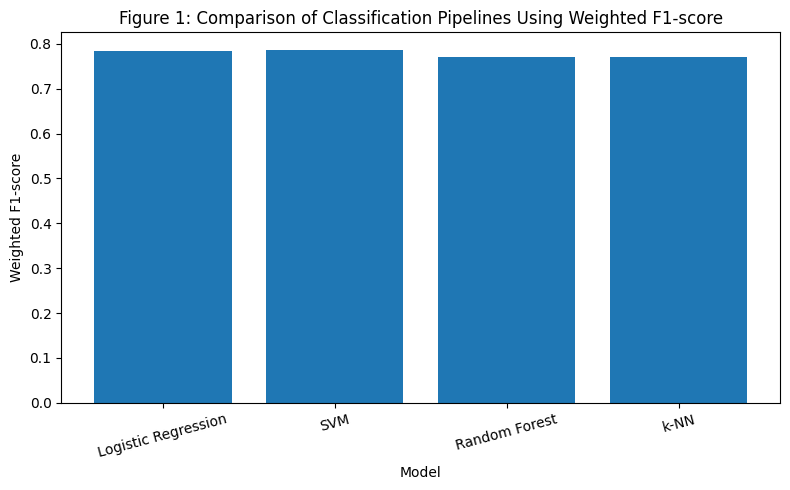

In [24]:
import matplotlib.pyplot as plt
#Bar gap
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["F1-score"])
plt.xlabel("Model")
plt.ylabel("Weighted F1-score")
plt.title("Figure 1: Comparison of Classification Pipelines Using Weighted F1-score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

This figure shows a visual comaprision of the weighted F! -scores obtained by each classification workflow.Among the models tested the Suppoer Vector Machine had the greatest weighted F1-score ,indicating the best over all balance of precision and recall across accident severity classes.Logistic Regression also demostrated competitive performance,while random forest and k-Nearest Neighbours scores lower under the selected configurations.

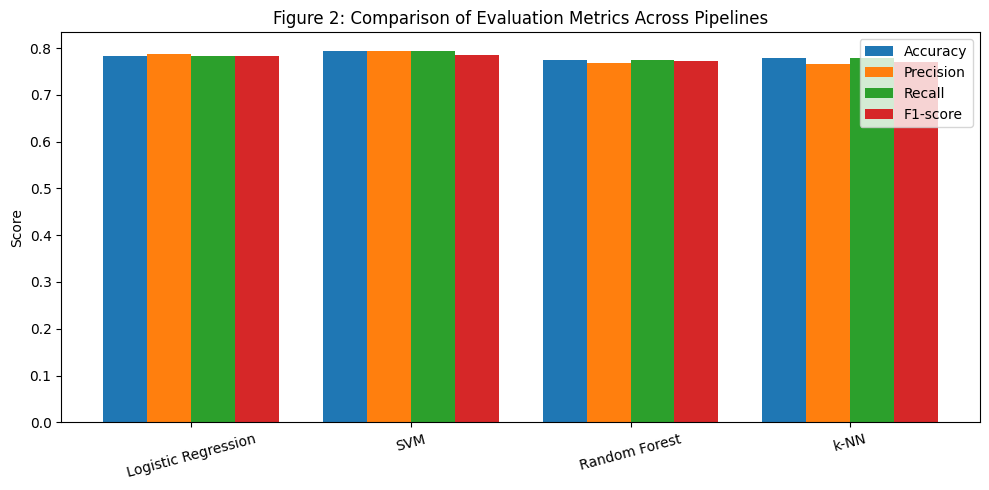

In [25]:
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
x = np.arange(len(results_df["Model"]))
width = 0.2

plt.figure(figsize=(10, 5))
for i, metric in enumerate(metrics):
    plt.bar(x + i*width, results_df[metric], width, label=metric)

plt.xticks(x + 1.5*width, results_df["Model"], rotation=15)
plt.ylabel("Score")
plt.title("Figure 2: Comparison of Evaluation Metrics Across Pipelines")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Discussion

The experimental results show that model selection has a mmeasurable impact on accident severity classification performance , even when using a consistent preprocessing and evaluation methodology.Among the pipelines tested, the support vector machine has the highest weighted F1-score, suggesting the best balanced performance across imbalanced severity categories.

The Support Vector Machine's higher performance can be attributed to its ability to model nonlinear decision boundries using the radial basis funstion kernel.Accident severity is influenced by complex interaction between demographic factors,vehicle safety measures, and behavioural variables such as alcohol use.Thse correlation are unlikely to be fully linear , which explains why SVM outperformed the Linear Logistic Regression baseline.

Despite its linear assumptions, Logistic Regressiomn demostrarted a good performance.This shows that additive linear connection when combined with adequate preprocessing such as feature scaling and categorical eencoding , can capture a considerable percentage of the dataset's pedictive signal.As a result ,logistic regression gives a reliable and understandabel baseline for this task.

SVM abd Logistic Regression performed marginally better than the Random Forest process. While Random Forests are capable of modelling non-linear interactions and noise resistant ,their effectivness may be reduced in high dimensional feature space fcreated by one-hot encoding of categorical variables .Additionally ,The default hyperparameter configuration used n this study may limit the model's ability to fully exploit complex patterns in the data.

The k-Nearest Neighbour pipeline has the lowest weighted F1-score of the models tested .he result is consistent with theoretical assumption ,given that the distance -based approaches are sensitive to feature dimensionality and sparsity.The large number of encode categorical features increases the dimentionality in input space,limiting discriminative efficacy of distance metrics even with feature scaling and distance- weighted voting.

Overall, the results show that models can capture nonlinear interactions while remaining robust on high-dimensional representation are better better suited for predicting accident severity on the FARS dataset.These finding emphasise the necessity of matching model assumptions to data features when devloping machine learnig pipelines for the real world categorisation problems.

## 8. Conclusion

This mini-project investigated the prediction of road traffic accident severity using four machine learning pipelines for predicting road traffic accident severity using the FARS datasets . To ensure fair comparison across models ,uniform preprocessing and evaluation approach was used. According to the results, Support Vector Machines performed the best overall, whereas Logistic Regression provides a baseline that was both competitive and interpretable.Thses findings demonstrate the importance of selecting models that align the structure and complexity of the data when dealing with imbalanced classification problems in the real world.